# 02 - Feature Engineering

基于采样后的交互数据，构建三类特征：
- **用户侧特征**：活跃度、关注/粉丝数、注册天数等
- **视频侧特征**：时长、类型、每日播放/点赞统计等
- **统计交叉特征**：用户历史行为均值、视频全局热度等

> **注意**：`item_daily_features` 是按日统计的特征，join 时需对齐交互日期，避免数据泄露。

In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

DATA_DIR = "./data/KuaiRec/data"
PROCESSED_DIR = "./data/processed"

## 1. 加载数据

In [2]:
# 加载采样后的交互数据
df = pd.read_parquet(f"{PROCESSED_DIR}/interactions_sampled.parquet")
print(f"Interactions shape : {df.shape}")
print(f"Positive rate      : {df['label'].mean():.2%}")
df.head(3)

Interactions shape : (994389, 9)
Positive rate      : 4.85%


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio,label
0,14,148,4381,6067,2020-07-04 21:27:48.378,20200705.0,1.593898e+09,0.722103,0
1,14,183,11635,6100,2020-07-04 21:28:00.057,20200705.0,1.593898e+09,1.907377,0
2,14,3649,22422,10867,2020-07-04 21:29:09.479,20200705.0,1.593898e+09,2.063311,1


In [3]:
# 加载用户特征
user_feat = pd.read_csv(f"{DATA_DIR}/user_features.csv")
print(f"User features shape: {user_feat.shape}")
user_feat.head(3)

User features shape: (7176, 31)


,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,...,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,...,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,...,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# 加载视频日统计特征（排除 ID/tag 类高基数列，其余全量保留）
ITEM_COLS = [
    'video_id', 'date',
    # 视频基础属性
    'video_type', 'upload_dt', 'upload_type', 'visible_status',
    'video_duration', 'video_width', 'video_height',
    # 曝光 & 播放
    'show_cnt', 'show_user_num',
    'play_cnt', 'play_user_num', 'play_duration',
    'complete_play_cnt', 'complete_play_user_num',
    'valid_play_cnt', 'valid_play_user_num',
    'long_time_play_cnt', 'long_time_play_user_num',
    'short_time_play_cnt', 'short_time_play_user_num',
    'play_progress', 'comment_stay_duration',
    # 点赞
    'like_cnt', 'like_user_num', 'click_like_cnt', 'double_click_cnt',
    'cancel_like_cnt', 'cancel_like_user_num',
    # 评论
    'comment_cnt', 'comment_user_num', 'direct_comment_cnt', 'reply_comment_cnt',
    'delete_comment_cnt', 'delete_comment_user_num',
    'comment_like_cnt', 'comment_like_user_num',
    # 关注 & 分享 & 下载
    'follow_cnt', 'follow_user_num', 'cancel_follow_cnt', 'cancel_follow_user_num',
    'share_cnt', 'share_user_num',
    'download_cnt', 'download_user_num',
    # 举报 & 减少相似 & 收藏
    'report_cnt', 'report_user_num',
    'reduce_similar_cnt', 'reduce_similar_user_num',
    'collect_cnt', 'collect_user_num',
    'cancel_collect_cnt', 'cancel_collect_user_num',
]
item_feat = pd.read_csv(f"{DATA_DIR}/item_daily_features.csv", usecols=ITEM_COLS)
print(f"Item daily features shape: {item_feat.shape}")
item_feat.head(3)

Item daily features shape: (343341, 54)


,video_id,date,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,show_cnt,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,14665,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,10883,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,7842,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN


In [5]:
# 加载视频类别
item_cat = pd.read_csv(f"{DATA_DIR}/item_categories.csv")
print(f"Item categories shape: {item_cat.shape}")
item_cat.head(3)

Item categories shape: (10728, 2)


,video_id,feat
0,0,[8]
1,1,"[27, 9]"
2,2,[9]


## 2. 日期对齐处理

`small_matrix` 中 `date` 格式为 `20200705.0`（float），
`item_daily_features` 中 `date` 格式为 `20200705`（int）。
需统一为字符串 `"20200705"` 后进行 join。

In [6]:
# 先丢弃 date 为 NaN 的行（无法对齐日统计特征）
df = df.dropna(subset=['date'])
df['date'] = df['date'].astype(float).astype(int).astype(str)
item_feat['date'] = item_feat['date'].astype(str)

print("Interaction date sample:", df['date'].iloc[0])
print("Item feat date sample  :", item_feat['date'].iloc[0])
print(f"Rows after dropna: {len(df):,}")

Interaction date sample: 20200705
Item feat date sample  : 20200705
Rows after dropna: 956,660


## 3. Join 用户特征

In [7]:
df = df.merge(user_feat, on='user_id', how='left')
print(f"After user join: {df.shape}")
print(f"User feature null rate: {df['user_active_degree'].isna().mean():.2%}")

After user join: (956660, 39)
User feature null rate: 0.00%


## 4. Join 视频日统计特征（日期对齐）

In [8]:
df = df.merge(item_feat, on=['video_id', 'date'], how='left')
print(f"After item join: {df.shape}")
print(f"Item feature null rate (play_cnt): {df['play_cnt'].isna().mean():.2%}")

After item join: (956660, 91)
Item feature null rate (play_cnt): 0.00%


## 5. Join 视频类别特征

In [9]:
# feat 列格式为字符串 "[8]"，解析为列表后取主类别
item_cat['feat_parsed'] = item_cat['feat'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) and x != '[]' else []
)
item_cat['main_category'] = item_cat['feat_parsed'].apply(
    lambda x: x[0] if len(x) > 0 else -1
)

df = df.merge(item_cat[['video_id', 'main_category']], on='video_id', how='left')
print(f"After category join: {df.shape}")

After category join: (956660, 92)


## 6. 衍生比率特征

基于 `item_daily_features` 的统计字段构造比率特征，不涉及 `watch_ratio`，无数据泄露风险。

> **注意**：原本计划构造 `user_avg_watch_ratio`、`video_avg_watch_ratio` 等统计交叉特征，
> 但由于标签来源正是 `watch_ratio`，全量计算会将测试集的目标值混入特征，导致严重数据泄露（实测 AUC → 1.0）。
> 正确做法是先切分数据集，仅在训练集上计算后 join 到验证/测试集，此处为保持结构简洁暂时去除。

In [10]:
# 视频完播率（由日统计特征衍生）
df['complete_play_rate'] = df['complete_play_cnt'] / (df['play_cnt'] + 1)
df['valid_play_rate'] = df['valid_play_cnt'] / (df['play_cnt'] + 1)
df['like_play_rate'] = df['like_cnt'] / (df['play_cnt'] + 1)

## 7. 类别特征编码

In [11]:
# 类别特征转为 pandas Categorical 类型
# LightGBM 能自动识别 category dtype，映射关系随 dtype 存储，无需单独保存 encoder
CAT_COLS = ['user_active_degree', 'video_type', 'upload_type']
for col in CAT_COLS:
    if col in df.columns:
        df[col] = df[col].astype('category')
        print(f"  {col}: {list(df[col].cat.categories)}")

  user_active_degree: ['UNKNOWN', 'full_active', 'high_active', 'middle_active']
  video_type: ['NORMAL']
  upload_type: ['AiCutVideo', 'FollowShoot', 'Kmovie', 'LongCamera', 'LongImport', 'LongPicture', 'PictureSet', 'ShortCamera', 'ShortImport', 'UNKNOWN', 'Web']


## 8. 特征选择与缺失值处理

In [12]:
# video_duration_y 缺失时，用同一 video_id 在其他天的时长填充（视频时长是固定值）
video_duration_map = item_feat.groupby('video_id')['video_duration'].first()
df['video_duration_y'] = df['video_duration_y'].fillna(df['video_id'].map(video_duration_map))
print(f"video_duration_y nulls after fix: {df['video_duration_y'].isna().sum()}")

# 丢弃非特征列（ID、时间戳、原始标签来源）
DROP_COLS = [
    'user_id', 'video_id', 'play_duration_x', 'video_duration_x',
    'time', 'date', 'timestamp', 'watch_ratio',
    'upload_dt',  # 日期字符串，需额外处理才能用，暂时 drop
]

feature_cols = [c for c in df.columns if c not in DROP_COLS + ['label']]

# 过滤常数列（全量数据中只有一个唯一值，对模型无贡献）
constant_cols = [c for c in feature_cols if df[c].nunique() <= 1]
if constant_cols:
    print(f"Dropping constant columns: {constant_cols}")
feature_cols = [c for c in feature_cols if c not in constant_cols]

print(f"Total features: {len(feature_cols)}")
print(feature_cols)

video_duration_y nulls after fix: 49345


Dropping constant columns: ['is_lowactive_period', 'is_live_streamer', 'onehot_feat5', 'video_type']
Total features: 81
['user_active_degree', 'is_video_author', 'follow_user_num_x', 'follow_user_num_range', 'fans_user_num', 'fans_user_num_range', 'friend_user_num', 'friend_user_num_range', 'register_days', 'register_days_range', 'onehot_feat0', 'onehot_feat1', 'onehot_feat2', 'onehot_feat3', 'onehot_feat4', 'onehot_feat6', 'onehot_feat7', 'onehot_feat8', 'onehot_feat9', 'onehot_feat10', 'onehot_feat11', 'onehot_feat12', 'onehot_feat13', 'onehot_feat14', 'onehot_feat15', 'onehot_feat16', 'onehot_feat17', 'upload_type', 'visible_status', 'video_duration_y', 'video_width', 'video_height', 'show_cnt', 'show_user_num', 'play_cnt', 'play_user_num', 'play_duration_y', 'complete_play_cnt', 'complete_play_user_num', 'valid_play_cnt', 'valid_play_user_num', 'long_time_play_cnt', 'long_time_play_user_num', 'short_time_play_cnt', 'short_time_play_user_num', 'play_progress', 'comment_stay_duration

In [13]:
df_features = df[feature_cols + ['label']].copy()

# 缺失值情况
null_rate = df_features.isna().mean().sort_values(ascending=False)
print("Top missing value columns:")
print(null_rate[null_rate > 0].head(20))

Top missing value columns:
cancel_collect_user_num    0.393600
cancel_collect_cnt         0.393600
collect_user_num           0.393600
collect_cnt                0.393600
video_duration_y           0.051580
onehot_feat4               0.029908
onehot_feat12              0.006711
onehot_feat13              0.003332
onehot_feat16              0.003332
onehot_feat15              0.003332
onehot_feat14              0.003332
onehot_feat17              0.003332
dtype: float64


In [14]:
# collect 系列：缺失代表该天无收藏数据（功能未上线或无埋点），填 0
collect_cols = ['collect_cnt', 'collect_user_num', 'cancel_collect_cnt', 'cancel_collect_user_num']
for col in collect_cols:
    if col in df_features.columns:
        df_features[col] = df_features[col].fillna(0)

# 其余数值特征用中位数填充
num_cols = df_features.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c != 'label']
df_features[num_cols] = df_features[num_cols].fillna(df_features[num_cols].median())

print(f"Remaining nulls: {df_features.isna().sum().sum()}")
print(f"Final dataset shape: {df_features.shape}")

Remaining nulls: 0
Final dataset shape: (956660, 82)


## 9. 特征分布概览

Top 3 most discriminative features:
  complete_play_rate: 0.1185
  play_progress: 0.0959
  video_duration_y: 0.0687


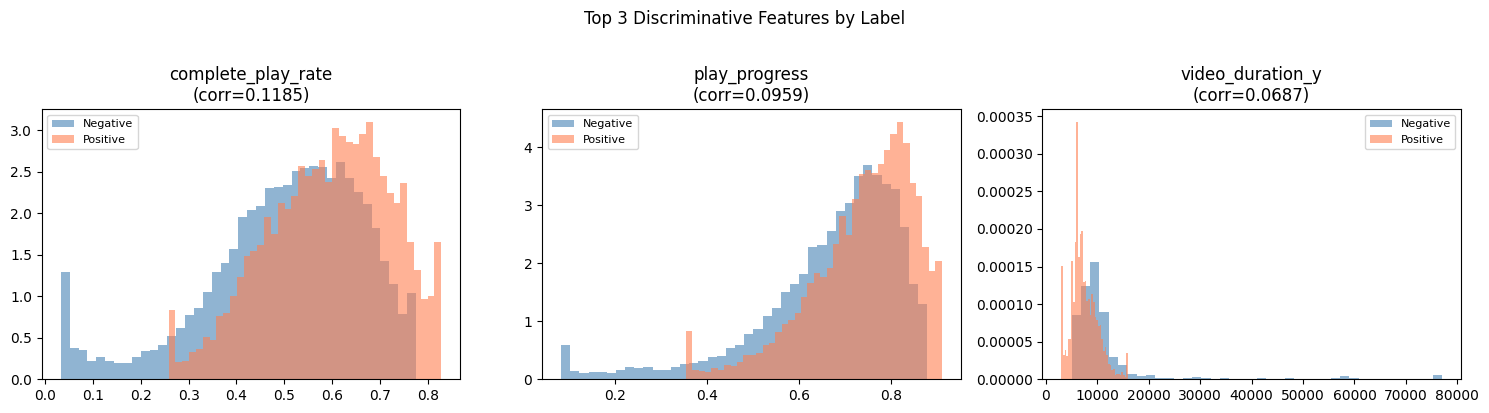

In [15]:
# 计算各特征与 label 的 point-biserial 相关性，取 top 3 有区分度的特征画图
from scipy.stats import pointbiserialr

num_feat_cols = df_features.select_dtypes(include=[np.number]).columns.tolist()
num_feat_cols = [c for c in num_feat_cols if c != 'label']

# 过滤常数列（方差为 0，相关性无意义）
num_feat_cols = [c for c in num_feat_cols if df_features[c].nunique() > 1]

correlations = {}
for col in num_feat_cols:
    corr, _ = pointbiserialr(df_features['label'], df_features[col].fillna(0))
    if not np.isnan(corr):
        correlations[col] = abs(corr)

top_features = sorted(correlations, key=correlations.get, reverse=True)[:3]
print("Top 3 most discriminative features:")
for f in top_features:
    print(f"  {f}: {correlations[f]:.4f}")

# 正负样本分布对比
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, feat in enumerate(top_features):
    for label_val, color, name in [(0, 'steelblue', 'Negative'), (1, 'coral', 'Positive')]:
        subset = df_features[df_features['label'] == label_val][feat]
        axes[i].hist(subset.clip(subset.quantile(0.01), subset.quantile(0.99)),
                     bins=40, alpha=0.6, color=color, label=name, density=True)
    axes[i].set_title(f"{feat}\n(corr={correlations[feat]:.4f})")
    axes[i].legend(fontsize=8)

plt.suptitle('Top 3 Discriminative Features by Label', y=1.02)
plt.tight_layout()
plt.show()

## 10. 保存特征

In [16]:
output_path = f"{PROCESSED_DIR}/features.parquet"
df_features.to_parquet(output_path, index=False)
print(f"Saved to {output_path}")
print(f"Shape: {df_features.shape}")
print(f"Positive rate: {df_features['label'].mean():.2%}")

Saved to ./data/processed/features.parquet
Shape: (956660, 82)
Positive rate: 4.87%
